In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import cv2
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
import scipy.io
from src.utils.custom_dataset import * # Load CustomDataset Class 
from src.utils.generate_operating_condition import *

In [5]:
BOUNDARY_PATH = "dataset/raw/Boundary/"
SOLVE_PATH = "dataset/raw/Solve/"
SUBD_PATH = "dataset/raw/Subd/"

boundary_lst = os.listdir(BOUNDARY_PATH)
solve_data_lst = os.listdir(SOLVE_PATH)
subd_data_lst = os.listdir(SUBD_PATH)

boundary type :<class 'numpy.ndarray'>
boundary shape :(101, 101)
----------------------------------------
solve type :<class 'pandas.core.frame.DataFrame'>
solve shape :(10069, 5)
----------------------------------------
subd type :<class 'numpy.ndarray'>
subd shape :(417, 624, 3)


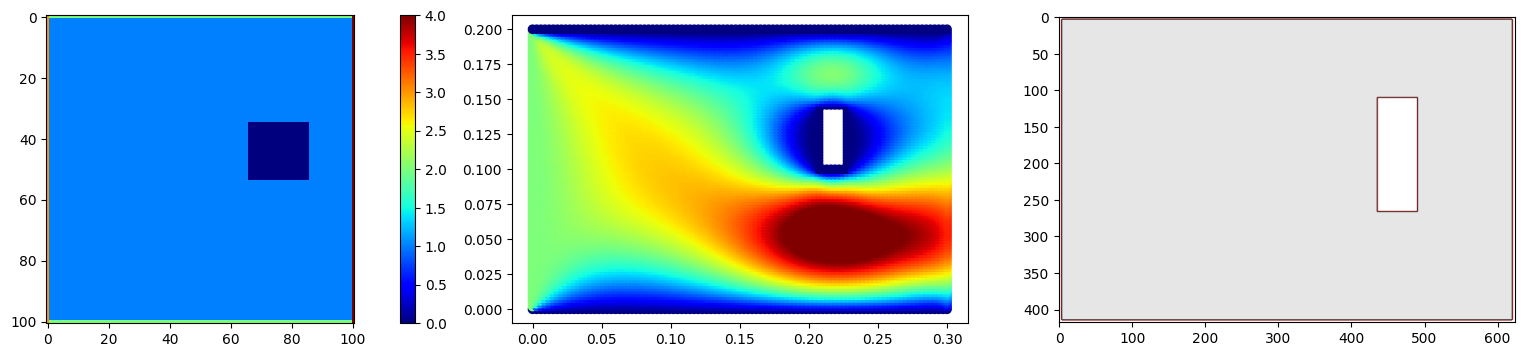

In [7]:
idx = 0

boundary = scipy.io.loadmat(BOUNDARY_PATH+boundary_lst[idx])
boundary = boundary['Boundary']
boundary = np.array(boundary)
boundary = np.where(boundary==5,0,boundary)
print(f"boundary type :{type(boundary)}")
print(f"boundary shape :{boundary.shape}")
plt.figure(figsize=[20,4])
plt.subplot(1,3,1)
plt.imshow(boundary,cmap='jet')
plt.colorbar(fraction=0.046, pad=0.1)
print("-"*40)

solve = pd.read_csv(SOLVE_PATH+solve_data_lst[idx])
print(f"solve type :{type(solve)}")
print(f"solve shape :{solve.shape}")
plt.subplot(1,3,2)
plt.scatter(solve["x"],solve["y"],c=solve["ux"],cmap='jet', vmin=0, vmax=10)
print("-"*40)

subd = cv2.imread(SUBD_PATH+subd_data_lst[idx])
print(f"subd type :{type(subd)}")
print(f"subd shape :{subd.shape}")
plt.subplot(1,3,3)
plt.imshow(subd)

In [3]:
# diff_y = 0.003
# diff_y = 0.002
# x_range = np.arange(0,0.3001,0.003)
# x_range = np.round(x_range,3)
# x_min, x_max = np.min(x_range), np.max(x_range)
# y_range = np.arange(0,0.2001,0.002)
# y_min, y_max = np.min(y_range), np.max(y_range)
# y_range = np.round(y_range,3)
# insert_x_lst = []
# insert_y_lst = []
# insert_ux_lst = []
# insert_uy_lst = []
# insert_p_lst = []
# boundary_lst = []

# for y in tqdm(y_range):
#     for x in x_range:
#         insert_x_lst.append(x)
#         insert_y_lst.append(y)
#         temp_df = solve[(solve["x"]==x) & (solve["y"]==y)]
#         if x==x_min:
#             boundary_lst.append(3)
#             insert_ux_lst.append(temp_df['ux'].values[0])
#             insert_uy_lst.append(temp_df['uy'].values[0])
#             insert_p_lst.append(temp_df['p'].values[0])
#         elif x==x_max:
#             boundary_lst.append(4)
#             insert_ux_lst.append(temp_df['ux'].values[0])
#             insert_uy_lst.append(temp_df['uy'].values[0])
#             insert_p_lst.append(temp_df['p'].values[0])            
#         elif y==y_min:
#             boundary_lst.append(2)
#             insert_ux_lst.append(temp_df['ux'].values[0])
#             insert_uy_lst.append(temp_df['uy'].values[0])
#             insert_p_lst.append(temp_df['p'].values[0])            
#         elif y==y_max:
#             boundary_lst.append(2)
#             insert_ux_lst.append(temp_df['ux'].values[0])
#             insert_uy_lst.append(temp_df['uy'].values[0])
#             insert_p_lst.append(temp_df['p'].values[0])            
#         else:
#             try:
#                 insert_ux_lst.append(temp_df['ux'].values[0])
#                 insert_uy_lst.append(temp_df['uy'].values[0])
#                 insert_p_lst.append(temp_df['p'].values[0])
#                 boundary_lst.append(1)  
#             except:
#                 insert_ux_lst.append(0)
#                 insert_uy_lst.append(0)
#                 insert_p_lst.append(0)
#                 boundary_lst.append(0)  

In [4]:
# new_df = pd.DataFrame({"x":insert_x_lst,"y":insert_y_lst,"ux":insert_ux_lst,"uy":insert_uy_lst,"p":insert_p_lst,'boundary':boundary_lst})
# plt.figure(figsize=[12,3])
# plt.subplot(1,2,1)
# plt.scatter(new_df["x"],new_df["y"],c=new_df["ux"],cmap='jet', vmin=0, vmax=10)
# plt.colorbar()
# plt.subplot(1,2,2)
# plt.scatter(new_df["x"],new_df["y"],c=new_df["boundary"],cmap='jet', vmin=0, vmax=5)
# plt.colorbar()

### 입출력데이터 생성(운전정보제외)

In [8]:
diff_y = 0.003
diff_y = 0.002
x_range = np.arange(0,0.3001,0.003)
x_range = np.round(x_range,3)
x_min, x_max = np.min(x_range), np.max(x_range)
y_range = np.arange(0,0.2001,0.002)
y_min, y_max = np.min(y_range), np.max(y_range)
y_range = np.round(y_range,3)
insert_x_lst = []
insert_y_lst = []
insert_ux_lst = []
insert_uy_lst = []
insert_p_lst = []
boundary_lst = []

solve_path = "dataset/raw/Solve/"
solve_data_lst = os.listdir(solve_path)
for solve_data in tqdm(solve_data_lst):
    solve = pd.read_csv(solve_path+solve_data)
    insert_x_lst = []
    insert_y_lst = []
    insert_ux_lst = []
    insert_uy_lst = []
    insert_p_lst = []
    boundary_lst = []
    for y in y_range:
        for x in x_range:
            insert_x_lst.append(x)
            insert_y_lst.append(y)
            temp_df = solve[(solve["x"]==x) & (solve["y"]==y)]
            if x==x_min:
                boundary_lst.append(3)
                insert_ux_lst.append(temp_df['ux'].values[0])
                insert_uy_lst.append(temp_df['uy'].values[0])
                insert_p_lst.append(temp_df['p'].values[0])
            elif x==x_max:
                boundary_lst.append(4)
                insert_ux_lst.append(temp_df['ux'].values[0])
                insert_uy_lst.append(temp_df['uy'].values[0])
                insert_p_lst.append(temp_df['p'].values[0])            
            elif y==y_min:
                boundary_lst.append(2)
                insert_ux_lst.append(temp_df['ux'].values[0])
                insert_uy_lst.append(temp_df['uy'].values[0])
                insert_p_lst.append(temp_df['p'].values[0])            
            elif y==y_max:
                boundary_lst.append(2)
                insert_ux_lst.append(temp_df['ux'].values[0])
                insert_uy_lst.append(temp_df['uy'].values[0])
                insert_p_lst.append(temp_df['p'].values[0])            
            else:
                try:
                    insert_ux_lst.append(temp_df['ux'].values[0])
                    insert_uy_lst.append(temp_df['uy'].values[0])
                    insert_p_lst.append(temp_df['p'].values[0])
                    boundary_lst.append(1)  
                except:
                    insert_ux_lst.append(0)
                    insert_uy_lst.append(0)
                    insert_p_lst.append(0)
                    boundary_lst.append(0)  
    new_df = pd.DataFrame({"x":insert_x_lst,"y":insert_y_lst,"ux":insert_ux_lst,"uy":insert_uy_lst,"p":insert_p_lst,'boundary':boundary_lst})
    new_df.to_csv(f"dataset/preprocessed/{solve_data}",index=False)                    

  1%|          | 5/550 [00:27<50:27,  5.55s/it]


KeyboardInterrupt: 

### 운전정보 데이터 생성

In [9]:
char2idx,idx2char = generate_operating_data()

In [10]:
char2idx

{'<PAD>': 0,
 '<UX>': 1,
 '<UY>': 2,
 '<DENSITY>': 3,
 '<VISCOSITY>': 4,
 '<NONE>': 5,
 '8': 6,
 '0': 7,
 '4': 8,
 '6': 9,
 '10': 10,
 '1': 11,
 '7': 12,
 '2': 13,
 '9': 14,
 '3': 15,
 '5': 16}